# ⏱️ Notebook 6 — Dynamic Monte Carlo: Gillespie's Method
| | |
|---|---|
| ⏱ Time | ~30 min |
| 🧭 Type | **Dynamic Monte Carlo** (book Ch. 4) |
| 🎯 You will learn | Gillespie's method · macroscopic → microscopic rate constants · control volume · simulate a batch **free-radical polymerization** in time |
| 🧰 Uses | Trick #3 (roulette wheel) + Trick #4 (waiting time) from Notebook 1 |
| 📖 Book | Sec. 4.5, Table 4.1, Algorithm 4.3 *Generic Gillespie Algorithm for Free Radical Polymerization* |

Notebooks 2–4 were **steady state** models: constant probabilities, chains built one after another, no time. In a batch reactor, monomer and initiator are consumed, so the rates change continuously. **Dynamic Monte Carlo** follows every reaction event on a clock and gives conversion vs. time, the number of radicals vs. time, and the MWD at any moment. Full details: *Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture*.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
random.seed(2)
plt.rcParams.update({"figure.figsize": (6, 3.6), "axes.grid": True, "grid.alpha": 0.3})
trapz = getattr(np, "trapezoid", None) or np.trapz
NA = 6.022e23

## 1 · Gillespie's method in 5 lines
```
loop:
    compute the Monte Carlo reaction rate (propensity) R_j^MC of every reaction channel
    R_tot^MC = Σ R_j^MC
    select reaction j with the roulette wheel                  (Trick #3)
    execute it (update the molecule counts)
    t ← t + ln(1/Rnd) / R_tot^MC                               (Trick #4)
```

### Warm-up: radioactive-style decay A → B
One reaction, rate `R = k · n_A`. Compare with the textbook `n_A(t) = n_A0 · e^(−kt)`.

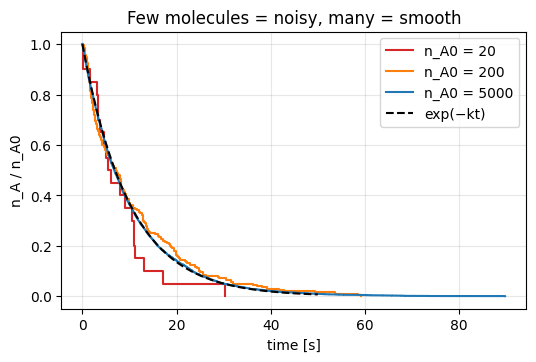

In [2]:
def decay(nA0, k):
    nA, t, ts, ns = nA0, 0.0, [0.0], [nA0]
    while nA > 0:
        R = k * nA
        t += np.log(1/random.random()) / R
        nA -= 1
        ts.append(t); ns.append(nA)
    return np.array(ts), np.array(ns)

k = 0.1
for nA0, c in [(20, "tab:red"), (200, "tab:orange"), (5000, "tab:blue")]:
    t, nA = decay(nA0, k)
    plt.step(t, nA/nA0, c=c, where="post", label=f"n_A0 = {nA0}")
tt = np.linspace(0, 50, 100)
plt.plot(tt, np.exp(-k*tt), "k--", label="exp(−kt)")
plt.xlabel("time [s]"); plt.ylabel("n_A / n_A0"); plt.legend(); plt.title("Few molecules = noisy, many = smooth"); plt.show()

## 2 · Macroscopic → microscopic rate constants (book Table 4.1)
We simulate a small **control volume** `V`. Concentrations become molecule counts: `n = [C]·N_A·V`.

| Reaction | Monte Carlo reaction rate | Microscopic rate constant |
|---|---|---|
| initiator decomposition, `I → 2R` | `R_d^MC = k_d^MC · n_I` | `k_d^MC = k_d` |
| initiation, `R + M → P₁` | `R_i^MC = k_i^MC · n_M · n_R` | `k_i^MC = k_i / (V·N_A)` |
| propagation, `Pₙ + M → Pₙ₊₁` | `R_p^MC = k_p^MC · n_M · n_P` | `k_p^MC = k_p / (V·N_A)` |
| transfer to monomer, `Pₙ + M → Dₙ + P₁` | `R_tM^MC = k_tM^MC · n_M · n_P` | `k_tM^MC = k_tM / (V·N_A)` |
| combination, `Pₙ + Pₘ → Dₙ₊ₘ` | `R_tc^MC = k_tc^MC · n_P(n_P − 1) / 4` | `k_tc^MC = 2k_tc / (V·N_A)` |

⚠️ **Illustrative parameters.** For realistic rate constants, the control volume must contain ~10⁹–10¹⁰ monomer molecules before it holds even a few polymer radicals (book Sec. 4.6, reproduced in Notebook 10). To run in about a second here, we use illustrative rate constants that give the same qualitative behaviour with 5 × 10⁵ monomer molecules and ~100 polymer radicals.

In [3]:
# ---- illustrative parameters (chosen for a fast run, not a specific monomer) ----
M0, I0 = 1.0, 0.04          # mol/L
f, kd = 0.5, 0.02           # initiator efficiency, 1/s
ki = kp = 400.0             # L/(mol s)
ktM = 0.4                   # transfer to monomer, L/(mol s)
ktc = 2e4                   # combination, L/(mol s)
nM0 = 500_000               # monomer molecules in the control volume

V = nM0 / (M0 * NA)
VNA = V * NA
kMC = dict(kd=kd, ki=ki/VNA, kp=kp/VNA, ktM=ktM/VNA, ktc=2*ktc/VNA)   # Table 4.1
nI0 = round(I0 * NA * V)
P_qssa = np.sqrt(2*f*kd*I0/ktc)                 # expected radical concentration
print(f"Control volume V = {V:.2e} L   →  n_M0 = {nM0:,},  n_I0 = {nI0:,}")
print(f"Expected number of polymer radicals n_P = [P]·N_A·V ≈ {P_qssa*VNA:.0f}  (book rule: must be well above 1)")

Control volume V = 8.30e-19 L   →  n_M0 = 500,000,  n_I0 = 20,000
Expected number of polymer radicals n_P = [P]·N_A·V ≈ 100  (book rule: must be well above 1)


## 3 · The free-radical polymerization simulation
Polymer radicals (living chains) are a Python list of chain lengths `P`; dead chains go into `dead`. Picking a random radical = picking a random index (all radicals react equally, whatever their length). The code follows Algorithm 4.3 line by line.

In [4]:
EVENTS = ["initiator decomposition", "chain initiation", "propagation", "transfer to monomer", "combination"]

def frp_gillespie(x_max=0.95, t_max=200, log_every=2000, verbose_first=0):
    nI, nR, nM = nI0, 0, nM0
    P, dead = [], []
    t, step = 0.0, 0
    hist = {"t": [], "x": [], "nP": [], "Mn": [], "PDI": []}
    s1 = s2 = 0                                    # running sums of dead lengths

    def take_random(lst):                          # remove & return a random element, O(1)
        k = random.randrange(len(lst)); val = lst[k]; lst[k] = lst[-1]; lst.pop(); return val

    while t < t_max and (nM0 - nM)/nM0 < x_max:
        nP = len(P)
        R = [kMC["kd"]*nI, kMC["ki"]*nR*nM, kMC["kp"]*nP*nM, kMC["ktM"]*nP*nM,
             kMC["ktc"]*nP*(nP-1)/4]                      # propensities, Table 4.1
        Rtot = sum(R)
        if Rtot == 0: break
        # roulette wheel
        r, j, acc = random.random()*Rtot, 0, R[0]
        while acc < r: j += 1; acc += R[j]
        # execute
        if j == 0:                                 # I → 2R (efficiency f)
            nI -= 1
            if random.random() <= f: nR += 2
        elif j == 1:                               # R + M → P1
            nR -= 1; nM -= 1; P.append(1)
        elif j == 2:                               # Pn + M → Pn+1
            k = random.randrange(nP); P[k] += 1; nM -= 1
        elif j == 3:                               # Pn + M → Dn + P1
            k = random.randrange(nP); dead.append(P[k]); s1 += P[k]; s2 += P[k]**2; P[k] = 1; nM -= 1
        else:                                      # Pn + Pm → D(n+m)
            L = take_random(P) + take_random(P); dead.append(L); s1 += L; s2 += L*L
        t += np.log(1/random.random()) / Rtot
        step += 1
        if step <= verbose_first:
            print(f"{step:3d}  t = {t:8.4f} s   {EVENTS[j]:<24s} n_M = {nM:,}  n_I = {nI:,}  n_R = {nR}  n_P = {len(P)}")
        if step % log_every == 0 and dead:
            hist["t"].append(t); hist["x"].append((nM0-nM)/nM0); hist["nP"].append(len(P))
            hist["Mn"].append(s1/len(dead)); hist["PDI"].append(s2*len(dead)/s1**2)
    return {k: np.array(v) for k, v in hist.items()}, np.array(dead), step

print("Event log of the first events — initiator decomposition must happen before anything else can:")
_ = frp_gillespie(x_max=1e-4, verbose_first=12)

Event log of the first events — initiator decomposition must happen before anything else can:
  1  t =   0.0014 s   initiator decomposition  n_M = 500,000  n_I = 19,999  n_R = 2  n_P = 0
  2  t =   0.0031 s   initiator decomposition  n_M = 500,000  n_I = 19,998  n_R = 2  n_P = 0
  3  t =   0.0032 s   initiator decomposition  n_M = 500,000  n_I = 19,997  n_R = 2  n_P = 0
  4  t =   0.0038 s   initiator decomposition  n_M = 500,000  n_I = 19,996  n_R = 2  n_P = 0
  5  t =   0.0039 s   chain initiation         n_M = 499,999  n_I = 19,996  n_R = 1  n_P = 1
  6  t =   0.0040 s   initiator decomposition  n_M = 499,999  n_I = 19,995  n_R = 3  n_P = 1
  7  t =   0.0045 s   initiator decomposition  n_M = 499,999  n_I = 19,994  n_R = 3  n_P = 1
  8  t =   0.0049 s   initiator decomposition  n_M = 499,999  n_I = 19,993  n_R = 5  n_P = 1
  9  t =   0.0057 s   chain initiation         n_M = 499,998  n_I = 19,993  n_R = 4  n_P = 2
 10  t =   0.0058 s   chain initiation         n_M = 499,997  n_I = 1

In [5]:
import time
t0 = time.time()
H, dead, steps = frp_gillespie()
print(f"{steps:,} events simulated in {time.time()-t0:.1f} s   |   dead chains: {len(dead):,}")

492,513 events simulated in 0.9 s   |   dead chains: 6,249


## 4 · ✅ Validation against the deterministic (ODE) model
For a large enough control volume, the average Monte Carlo behaviour must match the deterministic rate equations written with the same rate-constant convention (combination removes radicals at rate `k_tc[P]²`).

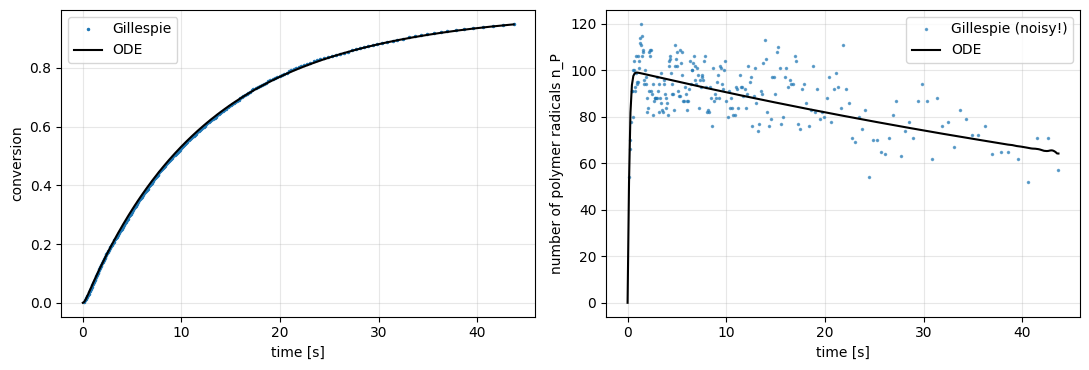

In [6]:
def odes(t, y):
    I, R, P, M = y
    return [-kd*I, 2*f*kd*I - ki*R*M, ki*R*M - ktc*P**2, -ki*R*M - (kp+ktM)*P*M]

sol = solve_ivp(odes, [0, H["t"][-1]], [I0, 0, 0, M0], method="LSODA", dense_output=True, rtol=1e-8)
tt = np.linspace(0, H["t"][-1], 300); I, R, Pr, M = sol.sol(tt)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(H["t"], H["x"], ".", ms=3, label="Gillespie"); ax[0].plot(tt, 1 - M/M0, "k-", label="ODE")
ax[0].set_xlabel("time [s]"); ax[0].set_ylabel("conversion"); ax[0].legend()
ax[1].plot(H["t"], H["nP"], ".", ms=3, alpha=0.6, label="Gillespie (noisy!)"); ax[1].plot(tt, Pr*NA*V, "k-", label="ODE")
ax[1].set_xlabel("time [s]"); ax[1].set_ylabel("number of polymer radicals n_P"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5 · What the ODE *can't* easily give you: the full MWD
Monte Carlo keeps every chain → averages *and* the complete distribution, at any time.

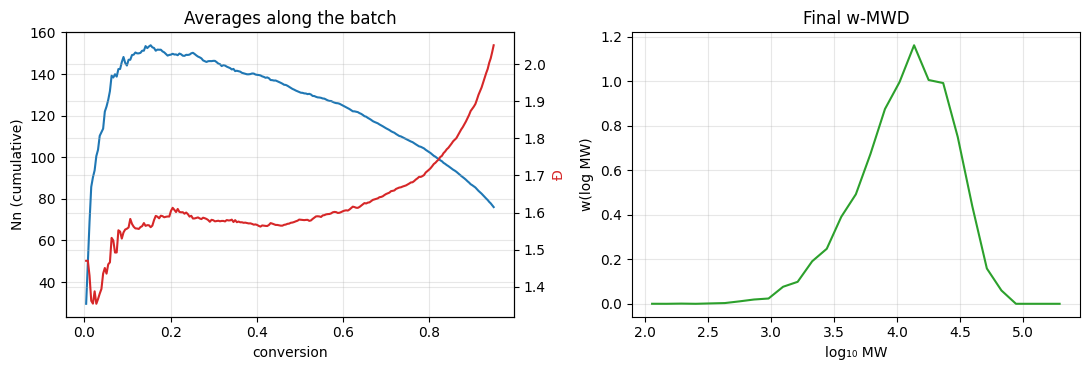

In [7]:
edges = np.logspace(0, np.log10(3*dead.max()), 30)          # extend past the longest chain
h, _ = np.histogram(dead, bins=edges, weights=dead)
x = np.log10(np.sqrt(edges[1:]*edges[:-1]) * 100.12)    # MMA-like repeat unit
y = h/np.diff(np.log10(edges)); y /= trapz(y, x)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(H["x"], H["Mn"], label="Nn"); ax2 = ax[0].twinx(); ax2.plot(H["x"], H["PDI"], c="tab:red", label="Đ")
ax[0].set_xlabel("conversion"); ax[0].set_ylabel("Nn (cumulative)"); ax2.set_ylabel("Đ", color="tab:red")
ax[0].set_title("Averages along the batch")
ax[1].plot(x, y, c="tab:green"); ax[1].set_xlabel("log₁₀ MW"); ax[1].set_ylabel("w(log MW)")
ax[1].set_title("Final w-MWD")
plt.tight_layout(); plt.show()

## ✅ Recap
- Gillespie's method = **propensities → roulette wheel → execute → advance the clock**.
- Bimolecular rate constants are divided by `V·N_A` (and combination needs the extra factors of Table 4.1).
- The **control volume** must hold enough polymer radicals (`n_P` well above 1), otherwise the simulation behaves like a tiny "nanoreactor" — see Notebook 10.
- Same answer as the ODE *on average*, plus noise and full chain-level detail.

### 🧪 Try it yourself
1. Set `ktM = 0` (only combination). What happens to Đ?
2. Raise `ktM` ten-fold. Which curve changes: conversion, Nn, or both?
3. Divide `nM0` by 100. How many radicals are left in the control volume, and what happens to the results?

➡️ **Next: Notebook 7 — Dynamic Monte Carlo: ATRP & polymer degradation**